# 07 — Statistical and Black-Box Machine Learning

## Objective

This notebook investigates statistical and black-box machine-learning models for predicting the MEMS acceleration from the available dynamical variables.

The prediction problem is formulated as

$$
(x,\dot{x},F)
\longrightarrow
\ddot{x}.
$$

Unlike classical system identification and equation-discovery methods, the models in this notebook are primarily evaluated according to predictive performance rather than direct recovery of the governing physical equation.

The analysis will compare models with different levels of flexibility, including:

- linear regression as a statistical baseline,
- polynomial regression for nonlinear relationships,
- tree-based ensemble regression as a black-box model.

The models will be evaluated using held-out data and quantitative error metrics such as RMSE, MAE, and coefficient of determination $R^2$.

This provides a predictive-machine-learning baseline for later probabilistic and physics-informed approaches.

In [1]:
# NOTEBOOK SETUP

from pathlib import Path
import sys


# Identify the project root directory.
PROJECT_ROOT = Path.cwd().parent


# Add the project root to Python's import path.
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(
        0,
        str(PROJECT_ROOT),
    )


# Standard scientific Python libraries.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# Scikit-learn tools.
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score,
)


# Project utilities.
from src.utils import (
    data_path,
    results_path,
    figures_path,
    ensure_directory,
)

In [2]:
# LOAD DATA AND CREATE A TIME-AWARE TRAIN/TEST SPLIT


baseline_data_path = (
    data_path("raw")
    / "deterministic_baseline.csv"
)

baseline_data = pd.read_csv(
    baseline_data_path
)


# Extract the model inputs.
#
# X = [displacement, velocity, excitation]
ml_input = np.column_stack(
    (
        baseline_data["displacement"].to_numpy(),
        baseline_data["velocity"].to_numpy(),
        baseline_data["excitation"].to_numpy(),
    )
)


# The prediction target is acceleration.
ml_target = baseline_data[
    "acceleration"
].to_numpy()


# Keep the corresponding time values for later plots.
ml_time = baseline_data[
    "time"
].to_numpy()



# TIME-AWARE SPLIT
train_fraction = 0.80

split_index = int(
    train_fraction
    * len(ml_input)
)


# First 80% for training.
X_train = ml_input[
    :split_index
]

y_train = ml_target[
    :split_index
]

time_train = ml_time[
    :split_index
]


# Final 20% for testing.
X_test = ml_input[
    split_index:
]

y_test = ml_target[
    split_index:
]

time_test = ml_time[
    split_index:
]


print(
    f"Total samples:    "
    f"{len(ml_input)}"
)

print(
    f"Training samples: "
    f"{len(X_train)}"
)

print(
    f"Testing samples:  "
    f"{len(X_test)}"
)

print()

print(
    f"Training time range: "
    f"{time_train[0]:.4f} s "
    f"to {time_train[-1]:.4f} s"
)

print(
    f"Testing time range:  "
    f"{time_test[0]:.4f} s "
    f"to {time_test[-1]:.4f} s"
)

Total samples:    20001
Training samples: 16000
Testing samples:  4001

Training time range: 0.0000 s to 1.5999 s
Testing time range:  1.6000 s to 2.0000 s


In [3]:
# TRAIN THE LINEAR REGRESSION BASELINE


# Create the linear regression model.
linear_model = LinearRegression()


# Train the model using the first 80% of the time series.
linear_model.fit(
    X_train,
    y_train,
)


# Predict acceleration for both the training and test data.
linear_train_prediction = linear_model.predict(
    X_train
)

linear_test_prediction = linear_model.predict(
    X_test
)


# Display the learned coefficients.
#
# The input-column order is:
#
# [displacement, velocity, excitation]
print(
    f"Displacement coefficient: "
    f"{linear_model.coef_[0]:.10f}"
)

print(
    f"Velocity coefficient:     "
    f"{linear_model.coef_[1]:.10f}"
)

print(
    f"Excitation coefficient:   "
    f"{linear_model.coef_[2]:.10f}"
)

print(
    f"Intercept:                "
    f"{linear_model.intercept_:.10f}"
)

Displacement coefficient: -1000.0000000000
Velocity coefficient:     -0.0800000000
Excitation coefficient:   1.0000000000
Intercept:                -0.0000000000


## Linear Regression Baseline

The linear regression model learned the coefficients

$$
-1000
$$

for displacement,

$$
-0.08
$$

for velocity, and

$$
1
$$

for excitation, with an intercept effectively equal to zero.

The learned predictive relationship is therefore

$$
\hat{\ddot{x}}
=
-1000x
-0.08\dot{x}
+F(t),
$$

which matches the known deterministic governing equation.

The model was trained only on the first 80% of the time series. Its performance on the held-out final 20% is evaluated next.

In [4]:
# EVALUATE THE LINEAR REGRESSION MODEL

# Training-set metrics.
linear_train_rmse = np.sqrt(
    mean_squared_error(
        y_train,
        linear_train_prediction,
    )
)

linear_train_mae = mean_absolute_error(
    y_train,
    linear_train_prediction,
)

linear_train_r2 = r2_score(
    y_train,
    linear_train_prediction,
)


# Test-set metrics.
linear_test_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        linear_test_prediction,
    )
)

linear_test_mae = mean_absolute_error(
    y_test,
    linear_test_prediction,
)

linear_test_r2 = r2_score(
    y_test,
    linear_test_prediction,
)


print(
    f"Training RMSE: "
    f"{linear_train_rmse:.12e}"
)

print(
    f"Training MAE:  "
    f"{linear_train_mae:.12e}"
)

print(
    f"Training R²:   "
    f"{linear_train_r2:.12f}"
)

print()

print(
    f"Testing RMSE:  "
    f"{linear_test_rmse:.12e}"
)

print(
    f"Testing MAE:   "
    f"{linear_test_mae:.12e}"
)

print(
    f"Testing R²:    "
    f"{linear_test_r2:.12f}"
)

Training RMSE: 3.701456385363e-14
Training MAE:  2.972377298568e-14
Training R²:   1.000000000000

Testing RMSE:  3.633532236011e-14
Testing MAE:   2.987481414255e-14
Testing R²:    1.000000000000


### Linear Regression Performance

The linear regression model achieved essentially perfect prediction on both the training and held-out test data.

The testing performance was

$$
\mathrm{RMSE}\approx3.63\times10^{-14},
$$

$$
\mathrm{MAE}\approx2.99\times10^{-14},
$$

and

$$
R^2=1.000000.
$$

The similarity between training and testing performance shows that the model generalizes across the time-aware split.

This result is expected because the deterministic baseline dynamics are exactly linear in displacement, velocity, and excitation, which matches the functional form of linear regression.

In [5]:
# TRAIN A SECOND-ORDER POLYNOMIAL REGRESSION MODEL


polynomial_model = Pipeline(
    steps=[
        (
            "polynomial_features",
            PolynomialFeatures(
                degree=2,
                include_bias=False,
            ),
        ),
        (
            "linear_regression",
            LinearRegression(),
        ),
    ]
)


# Train the model.
polynomial_model.fit(
    X_train,
    y_train,
)


# Generate predictions.
polynomial_train_prediction = (
    polynomial_model.predict(
        X_train
    )
)

polynomial_test_prediction = (
    polynomial_model.predict(
        X_test
    )
)


# Calculate performance metrics.
polynomial_train_rmse = np.sqrt(
    mean_squared_error(
        y_train,
        polynomial_train_prediction,
    )
)

polynomial_test_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        polynomial_test_prediction,
    )
)

polynomial_test_mae = mean_absolute_error(
    y_test,
    polynomial_test_prediction,
)

polynomial_test_r2 = r2_score(
    y_test,
    polynomial_test_prediction,
)


print(
    f"Polynomial training RMSE: "
    f"{polynomial_train_rmse:.12e}"
)

print(
    f"Polynomial testing RMSE:  "
    f"{polynomial_test_rmse:.12e}"
)

print(
    f"Polynomial testing MAE:   "
    f"{polynomial_test_mae:.12e}"
)

print(
    f"Polynomial testing R²:    "
    f"{polynomial_test_r2:.12f}"
)

Polynomial training RMSE: 3.887187587676e-14
Polynomial testing RMSE:  3.629878907225e-14
Polynomial testing MAE:   2.992659483620e-14
Polynomial testing R²:    1.000000000000


### Polynomial Regression Performance

The second-order polynomial regression model achieved essentially the same predictive accuracy as the linear regression baseline.

The testing performance was

$$
\mathrm{RMSE}\approx3.63\times10^{-14},
$$

$$
\mathrm{MAE}\approx2.99\times10^{-14},
$$

and

$$
R^2=1.000000.
$$

The additional polynomial features therefore provided no measurable predictive benefit for the deterministic baseline, whose true dynamics are exactly linear in displacement, velocity, and excitation.

The learned polynomial coefficients are examined next to determine whether the unnecessary nonlinear terms received coefficients close to zero.

In [7]:
# INSPECT THE POLYNOMIAL REGRESSION COEFFICIENTS

# Retrieve the generated polynomial feature names.
polynomial_feature_names = (
    polynomial_model
    .named_steps["polynomial_features"]
    .get_feature_names_out(
        [
            "x",
            "x_dot",
            "F",
        ]
    )
)


# Retrieve the corresponding linear-regression coefficients.
polynomial_coefficients = (
    polynomial_model
    .named_steps["linear_regression"]
    .coef_
)


# Create a readable coefficient table.
polynomial_coefficient_table = pd.DataFrame(
    {
        "feature": polynomial_feature_names,
        "coefficient": polynomial_coefficients,
    }
)


polynomial_coefficient_table

,feature,coefficient
0,x,-1.000000e+03
1,x_dot,-8.000000e-02
2,F,1.000000e+00
3,x^2,4.675458e-10
4,x x_dot,-2.939980e-13
5,x F,1.806180e-12
6,x_dot^2,5.340173e-13
7,x_dot F,-3.122069e-14
8,F^2,-2.886580e-15


### Polynomial Coefficient Interpretation

The polynomial regression model retained the physically meaningful linear coefficients

$$
-1000
$$

for displacement,

$$
-0.08
$$

for velocity, and

$$
1
$$

for excitation.

All second-order polynomial terms received coefficients extremely close to zero.

For example,

$$
x^2
$$

received a coefficient on the order of

$$
10^{-10},
$$

while the remaining interaction and quadratic terms were approximately between

$$
10^{-12}
$$

and

$$
10^{-15}.
$$

This confirms that the additional nonlinear polynomial features are not required for the deterministic baseline.

The result is consistent with the known governing dynamics, which are linear in displacement, velocity, and excitation.

In [8]:
# TRAIN A RANDOM FOREST REGRESSION MODEL


random_forest_model = RandomForestRegressor(
    n_estimators=200,
    random_state=9512,
    n_jobs=-1,
)


# Train the model using the same time-aware training data.
random_forest_model.fit(
    X_train,
    y_train,
)


# Generate predictions.
random_forest_train_prediction = (
    random_forest_model.predict(
        X_train
    )
)

random_forest_test_prediction = (
    random_forest_model.predict(
        X_test
    )
)



# CALCULATE PERFORMANCE METRICS
random_forest_train_rmse = np.sqrt(
    mean_squared_error(
        y_train,
        random_forest_train_prediction,
    )
)

random_forest_test_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        random_forest_test_prediction,
    )
)

random_forest_test_mae = mean_absolute_error(
    y_test,
    random_forest_test_prediction,
)

random_forest_test_r2 = r2_score(
    y_test,
    random_forest_test_prediction,
)


print(
    f"Random Forest training RMSE: "
    f"{random_forest_train_rmse:.12e}"
)

print(
    f"Random Forest testing RMSE:  "
    f"{random_forest_test_rmse:.12e}"
)

print(
    f"Random Forest testing MAE:   "
    f"{random_forest_test_mae:.12e}"
)

print(
    f"Random Forest testing R²:    "
    f"{random_forest_test_r2:.12f}"
)

Random Forest training RMSE: 2.912667778733e-03
Random Forest testing RMSE:  1.831217155072e-01
Random Forest testing MAE:   1.202641121270e-01
Random Forest testing R²:    0.997097413010


### Random Forest Performance

The Random Forest achieved a very high predictive accuracy overall, with a testing coefficient of determination of

$$
R^2 \approx 0.9971.
$$

However, its training and testing errors differed substantially.

The training RMSE was approximately

$$
0.00291,
$$

whereas the testing RMSE increased to approximately

$$
0.1831.
$$

The testing MAE was approximately

$$
0.1203.
$$

This indicates that the Random Forest fitted the training region very accurately but generalized less precisely to the later part of the time series.

Unlike linear regression, a Random Forest does not explicitly represent the governing linear equation. It instead learns piecewise relationships from the observed training data. This makes it highly flexible for interpolation but generally less suitable for extrapolating beyond the combinations of state variables encountered during training.

The result therefore illustrates that a more flexible black-box model does not necessarily outperform a simpler model when the simpler model is structurally well matched to the underlying physics.

In [13]:
# RANDOM FOREST FEATURE IMPORTANCE


feature_names = [
    "displacement",
    "velocity",
    "excitation",
]


random_forest_feature_importance = pd.DataFrame(
    {
        "feature": feature_names,
        "importance": random_forest_model.feature_importances_,
    }
)


# Sort from most important to least important.
random_forest_feature_importance = (
    random_forest_feature_importance
    .sort_values(
        by="importance",
        ascending=False,
    )
    .reset_index(
        drop=True
    )
)


random_forest_feature_importance

,feature,importance
0,displacement,0.958353
1,excitation,0.039783
2,velocity,0.001865


### Random Forest Feature Importance

The Random Forest assigned the largest importance to displacement:

$$
0.9584.
$$

Excitation had a smaller but still meaningful importance of approximately

$$
0.0398,
$$

while velocity received only

$$
0.00187.
$$

This ranking is consistent with the relative physical contributions in the governing dynamics. The stiffness contribution associated with displacement dominates the acceleration response, while the damping contribution associated with velocity is comparatively weak.

The result therefore shows that, although the Random Forest does not explicitly recover the governing equation, its learned feature-importance ranking is qualitatively consistent with the dominant physical mechanisms of the simulated system.

In [15]:
# COMPARE MACHINE-LEARNING MODELS


ml_model_comparison = pd.DataFrame(
    {
        "model": [
            "Linear regression",
            "Polynomial regression",
            "Random Forest",
        ],

        "training_rmse": [
            linear_train_rmse,
            polynomial_train_rmse,
            random_forest_train_rmse,
        ],

        "testing_rmse": [
            linear_test_rmse,
            polynomial_test_rmse,
            random_forest_test_rmse,
        ],

        "testing_mae": [
            linear_test_mae,
            polynomial_test_mae,
            random_forest_test_mae,
        ],

        "testing_r2": [
            linear_test_r2,
            polynomial_test_r2,
            random_forest_test_r2,
        ],
    }
)


ml_model_comparison

,model,training_rmse,testing_rmse,testing_mae,testing_r2
0,Linear regression,3.701456e-14,3.633532e-14,2.987481e-14,1.000000
1,Polynomial regression,3.887188e-14,3.629879e-14,2.992659e-14,1.000000
2,Random Forest,2.912668e-03,1.831217e-01,1.202641e-01,0.997097


In [16]:
# SAVE MACHINE-LEARNING RESULTS


# Create the results directory for this notebook.
machine_learning_results_directory = results_path(
    "machine_learning"
)

ensure_directory(
    machine_learning_results_directory
)



# SAVE MODEL PERFORMANCE COMPARISON
model_comparison_path = (
    machine_learning_results_directory
    / "deterministic_model_performance.csv"
)

ml_model_comparison.to_csv(
    model_comparison_path,
    index=False,
)



# SAVE POLYNOMIAL COEFFICIENTS
polynomial_coefficients_path = (
    machine_learning_results_directory
    / "polynomial_regression_coefficients.csv"
)

polynomial_coefficient_table.to_csv(
    polynomial_coefficients_path,
    index=False,
)



# SAVE RANDOM FOREST FEATURE IMPORTANCE
random_forest_importance_path = (
    machine_learning_results_directory
    / "random_forest_feature_importance.csv"
)

random_forest_feature_importance.to_csv(
    random_forest_importance_path,
    index=False,
)


print("Model comparison saved to:")
print(model_comparison_path)

print()

print("Polynomial coefficients saved to:")
print(polynomial_coefficients_path)

print()

print("Random Forest feature importance saved to:")
print(random_forest_importance_path)

Model comparison saved to:
D:\Uni\Mechanical Enginnering Masters\Extra\Data Analysis and Info Engineering\Part II Information Engineering\monte_carlo_mems_sciml\results\machine_learning\deterministic_model_performance.csv

Polynomial coefficients saved to:
D:\Uni\Mechanical Enginnering Masters\Extra\Data Analysis and Info Engineering\Part II Information Engineering\monte_carlo_mems_sciml\results\machine_learning\polynomial_regression_coefficients.csv

Random Forest feature importance saved to:
D:\Uni\Mechanical Enginnering Masters\Extra\Data Analysis and Info Engineering\Part II Information Engineering\monte_carlo_mems_sciml\results\machine_learning\random_forest_feature_importance.csv


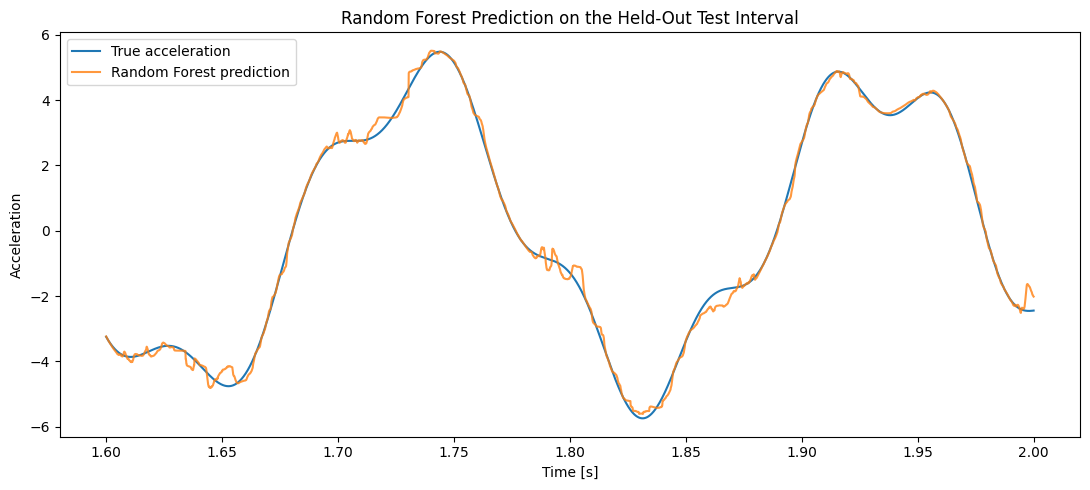

Random Forest test-prediction figure saved to:
D:\Uni\Mechanical Enginnering Masters\Extra\Data Analysis and Info Engineering\Part II Information Engineering\monte_carlo_mems_sciml\figures\machine_learning\random_forest_test_prediction.png


In [17]:
# PLOT RANDOM FOREST PREDICTIONS ON THE TEST INTERVAL


plt.figure(
    figsize=(11, 5)
)

# Plot the true acceleration.
plt.plot(
    time_test,
    y_test,
    label="True acceleration",
)

# Plot the Random Forest prediction.
plt.plot(
    time_test,
    random_forest_test_prediction,
    label="Random Forest prediction",
    alpha=0.8,
)

plt.xlabel(
    "Time [s]"
)

plt.ylabel(
    "Acceleration"
)

plt.title(
    "Random Forest Prediction on the Held-Out Test Interval"
)

plt.legend()

plt.tight_layout()



# SAVE THE FIGURE
machine_learning_figure_directory = figures_path(
    "machine_learning"
)

ensure_directory(
    machine_learning_figure_directory
)


random_forest_prediction_figure_path = (
    machine_learning_figure_directory
    / "random_forest_test_prediction.png"
)

plt.savefig(
    random_forest_prediction_figure_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()


print(
    "Random Forest test-prediction figure saved to:"
)

print(
    random_forest_prediction_figure_path
)

### Random Forest Test Prediction

The Random Forest reproduces the overall acceleration trajectory on the held-out test interval with high accuracy.

However, small local deviations are visible, particularly around regions where the signal changes more rapidly. Some predictions also appear slightly piecewise or step-like, which is consistent with the tree-based structure of the model.

This visual behaviour agrees with the numerical evaluation:

$$
R^2 \approx 0.9971,
$$

while the testing RMSE is approximately

$$
0.183.
$$

The model therefore captures the global response very well but does not reproduce the deterministic governing relationship as precisely as the linear and polynomial regression models.

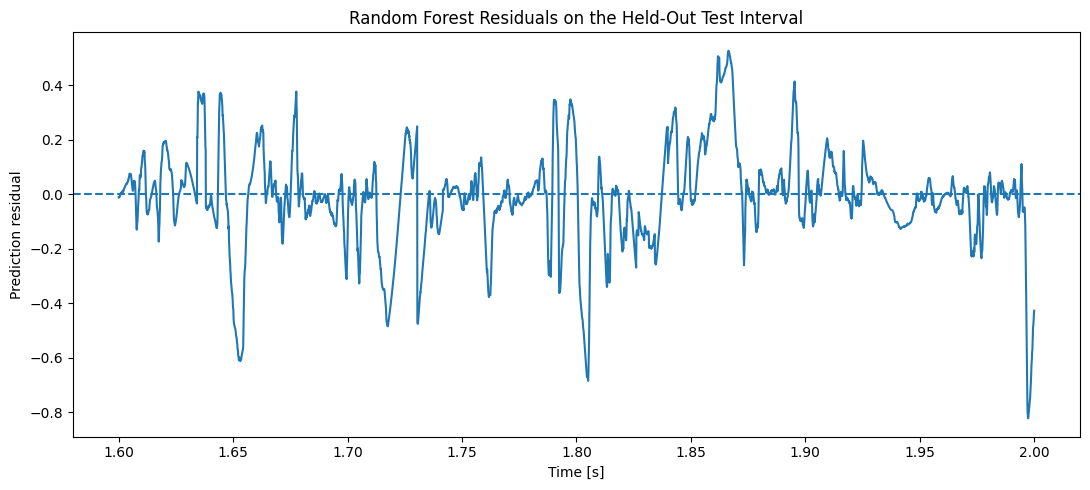

Residual mean: -1.269475625245e-02
Residual standard deviation: 1.826811590011e-01
Maximum absolute residual: 8.227491971315e-01

Residual figure saved to:
D:\Uni\Mechanical Enginnering Masters\Extra\Data Analysis and Info Engineering\Part II Information Engineering\monte_carlo_mems_sciml\figures\machine_learning\random_forest_test_residuals.png


In [18]:
# RANDOM FOREST TEST RESIDUALS
random_forest_test_residual = (
    y_test
    - random_forest_test_prediction
)


plt.figure(
    figsize=(11, 5)
)

plt.plot(
    time_test,
    random_forest_test_residual,
)

plt.axhline(
    0.0,
    linestyle="--",
)

plt.xlabel(
    "Time [s]"
)

plt.ylabel(
    "Prediction residual"
)

plt.title(
    "Random Forest Residuals on the Held-Out Test Interval"
)

plt.tight_layout()


# Save the residual figure.
random_forest_residual_figure_path = (
    machine_learning_figure_directory
    / "random_forest_test_residuals.png"
)

plt.savefig(
    random_forest_residual_figure_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()



# RESIDUAL STATISTICS
random_forest_residual_mean = np.mean(
    random_forest_test_residual
)

random_forest_residual_std = np.std(
    random_forest_test_residual
)

random_forest_residual_max = np.max(
    np.abs(
        random_forest_test_residual
    )
)


print(
    f"Residual mean: "
    f"{random_forest_residual_mean:.12e}"
)

print(
    f"Residual standard deviation: "
    f"{random_forest_residual_std:.12e}"
)

print(
    f"Maximum absolute residual: "
    f"{random_forest_residual_max:.12e}"
)

print()

print(
    "Residual figure saved to:"
)

print(
    random_forest_residual_figure_path
)

### Random Forest Residual Analysis

The Random Forest residuals on the held-out test interval had a mean of approximately

$$
-0.0127,
$$

indicating only a small overall prediction bias.

The residual standard deviation was approximately

$$
0.1827,
$$

and the maximum absolute residual reached approximately

$$
0.823.
$$

The residuals are concentrated around zero overall, but several localized peaks and structured deviations are visible.

This indicates that the prediction error is not uniformly distributed over the test interval. The Random Forest performs very well over much of the trajectory but experiences larger errors in particular regions of the dynamical response.

This behaviour is consistent with the piecewise nature of tree-based regression and with the use of a time-aware test interval that contains system states not represented in exactly the same way during training.

In [19]:
# VERIFY THE REUSABLE ML FUNCTIONS

from src.ml_models import (
    create_time_aware_split,
    train_linear_regression,
    train_polynomial_regression,
    train_random_forest,
    calculate_regression_metrics,
)


# Recreate the same time-aware split.
(
    X_train_check,
    X_test_check,
    y_train_check,
    y_test_check,
    time_train_check,
    time_test_check,
) = create_time_aware_split(
    ml_input,
    ml_target,
    ml_time,
    train_fraction=0.80,
)


# Train the reusable linear model.
linear_model_check = train_linear_regression(
    X_train_check,
    y_train_check,
)


# Predict on the test data.
linear_prediction_check = linear_model_check.predict(
    X_test_check
)


# Calculate the test metrics.
linear_metrics_check = calculate_regression_metrics(
    y_test_check,
    linear_prediction_check,
)


print(
    "Reusable-function linear regression:"
)

print(
    f"RMSE: "
    f"{linear_metrics_check['rmse']:.12e}"
)

print(
    f"MAE:  "
    f"{linear_metrics_check['mae']:.12e}"
)

print(
    f"R²:   "
    f"{linear_metrics_check['r2']:.12f}"
)

Reusable-function linear regression:
RMSE: 3.633532236011e-14
MAE:  2.987481414255e-14
R²:   1.000000000000


In [20]:
# FINAL OUTPUT VALIDATION FOR NOTEBOOK 07


notebook_07_outputs = {
    "model_performance_table":
        model_comparison_path,

    "polynomial_coefficients":
        polynomial_coefficients_path,

    "random_forest_feature_importance":
        random_forest_importance_path,

    "random_forest_prediction_figure":
        random_forest_prediction_figure_path,

    "random_forest_residual_figure":
        random_forest_residual_figure_path,
}


for output_name, output_path in notebook_07_outputs.items():

    print(
        f"{output_name:40s} "
        f"{output_path.exists()}"
    )

model_performance_table                  True
polynomial_coefficients                  True
random_forest_feature_importance         True
random_forest_prediction_figure          True
random_forest_residual_figure            True


# Notebook 07 Summary

This notebook evaluated statistical and black-box machine-learning approaches for predicting MEMS acceleration from displacement, velocity, and excitation.

The prediction problem was formulated as

$$
(x,\dot{x},F)
\longrightarrow
\ddot{x}.
$$

A time-aware train/test split was used, with the first 80% of the trajectory used for training and the final 20% reserved for testing.

## Linear Regression

Linear regression recovered the governing relationship essentially exactly:

$$
\hat{\ddot{x}}
=
-1000x
-0.08\dot{x}
+F(t).
$$

The held-out test performance was

$$
\mathrm{RMSE}\approx3.63\times10^{-14},
$$

$$
\mathrm{MAE}\approx2.99\times10^{-14},
$$

and

$$
R^2=1.000000.
$$

This near-perfect result is expected because the deterministic baseline is exactly linear in displacement, velocity, and excitation.

## Polynomial Regression

Second-order polynomial regression achieved essentially identical predictive performance.

The nonlinear and interaction terms received coefficients close to zero, while the physically meaningful linear terms retained coefficients of approximately

$$
-1000,\qquad -0.08,\qquad 1.
$$

The additional nonlinear flexibility therefore provided no measurable benefit for the deterministic linear baseline.

## Random Forest Regression

The Random Forest achieved high predictive accuracy, with

$$
R^2\approx0.9971,
$$

but its test error was substantially larger than for the linear models.

The training RMSE was approximately

$$
0.00291,
$$

while the testing RMSE increased to approximately

$$
0.1831.
$$

The Random Forest therefore fitted the training region very closely but generalized less precisely to the later part of the trajectory.

Its feature-importance ranking was

$$
\text{displacement} > \text{excitation} > \text{velocity},
$$

which is qualitatively consistent with the relative magnitude of the physical contributions in the governing equation.

Residual analysis showed a small overall bias but localized regions of larger prediction error, with a maximum absolute test residual of approximately

$$
0.823.
$$

## Main Finding

For this deterministic baseline, the simplest physically compatible statistical model performed best.

Linear regression reproduced the governing dynamics to numerical precision, while the more flexible Random Forest remained highly accurate but did not match the extrapolation and structural consistency of the linear model.

The results demonstrate that increased model complexity does not automatically improve prediction when a simpler model already matches the underlying system structure.

These deterministic predictive baselines provide a reference for the probabilistic and uncertainty-aware models developed in the following notebooks.